# Ground-motion prediction with a Kalman filter

Select one event, then run the notebook from top to bottom:
1. GMPE prediction.
2. Observed final PGA distribution.
3. Least-square fitting of the GMPE prediction.
4. Kalman-filter updates using time-dependent station PGA.

PGA is in gal (cm/s²), distances in km and Vs30 in m/s. The filter estimates
`[c2, c1, c_vs30, c0, c_cos, c_sin]` in natural-log PGA space.

In [7]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pygmt

ROOT = Path.cwd().resolve()
if not (ROOT / "earthquake_index.csv").is_file():
    ROOT = ROOT.parent
if not (ROOT / "earthquake_index.csv").is_file():
    raise FileNotFoundError("Run from publication_release or its notebook directory.")
sys.path.insert(0, str(ROOT / "GMPE code"))
sys.path.insert(0, str(ROOT))
from GMPE_Chao19 import Chao19H
from vdist import vdist


## Event and filter settings

| ID | Event | Source event time |
| --- | --- | --- |
| 1 | Hualien | 20240402T2358 |
| 2 | Kumamoto | 20260728T1627 |
| 3 | Meinong | 20160205T1957 |
| 4 | Chishang | 20220918T0644 |
| 5 | Kumamoto | 20160416T0125 |

Initial magnitudes, start times and the event-2 station exclusion follow the
source notebook's five-event calculation. Taiwan uses Chao; Japan uses Zhao06.

In [8]:
EVENT_ID = 5
END_SECOND = 40  # inclusive; available input times are 5–149 s
OBS_VARIANCE = 1e-4
Q = np.diag([1e-8, 1e-7, 5e-5, 1e-5, 5e-5, 5e-5])
VS_TRUE = 3.0  # vertical S-wave speed, km/s
V_APP = 2.6    # horizontal PGA-front speed, km/s
MIN_STATIONS = 5

EVENT_SETTINGS = {
    1: dict(gmpe="Chao", magnitude=6.2, start=5, exclude=None),
    2: dict(gmpe="Zhao06", magnitude=6.3, start=5, exclude=None),
    3: dict(gmpe="Chao", magnitude=6.1, start=13, exclude=None),
    4: dict(gmpe="Chao", magnitude=6.2, start=10, exclude=None),
    5: dict(gmpe="Zhao06", magnitude=5.9, start=5, exclude=None),
}
settings = EVENT_SETTINGS[EVENT_ID]
events = pd.read_csv(ROOT / "earthquake_index.csv", index_col="num")
event = events.loc[EVENT_ID]
event_key = event["time"].replace("T", "")
data = pd.read_csv(
    ROOT / "RuptureParaTime_new" / f"{event_key}_RuptureParaTimeByStation_new.csv",
    index_col=0,
)
if settings["exclude"] is not None:
    data = data[data["Station"] != settings["exclude"]].copy()

depth = float(event["hypodepth"])
distance_m, azimuth, _ = vdist(
    np.full(len(data), float(event["hypolat"])),
    np.full(len(data), float(event["hypolon"])),
    data["Latitude"].to_numpy(), data["Longitude"].to_numpy(),
)
data["SRepi"] = distance_m / 1000
data["SRhypo"] = np.sqrt(data["SRepi"] ** 2 + depth ** 2)
data["Azimuth"] = azimuth
stations = data.loc[[settings["start"]]].copy()

def design_matrix(frame, directional=True):
    ln_r = np.log(frame["SRhypo"].to_numpy())
    terms = [ln_r**2, ln_r, np.log(frame["Vs30"].to_numpy() / 760), np.ones(len(frame))]
    if directional:
        theta = np.deg2rad(frame["Azimuth"].to_numpy())
        terms.extend([np.cos(theta), np.sin(theta)])
    return np.column_stack(terms)

print(f"Event {EVENT_ID}: {event['time']}, {settings['gmpe']}, {len(stations)} stations")


Event 5: 20160416T0125, Zhao06, 266 stations


## 1. GMPE prediction

Evaluate the initial EEW magnitude and show its predicted PGA on the original map. As in the source
workflow, hypocentral distance is used as a point-source approximation to Rrup.
Chao predictions are converted from g to gal with `980 × 1.22`; Zhao06 already
returns gal and retains the source workflow's factor of `1.2`.

surface [WARNING]: 22 unusable points were supplied; these will be ignored.
surface [WARNING]: You should have pre-processed the data with block-mean, -median, or -mode.
surface [WARNING]: Check that previous processing steps write results with enough decimals.
surface [WARNING]: Possibly some data were half-way between nodes and subject to IEEE 754 rounding.


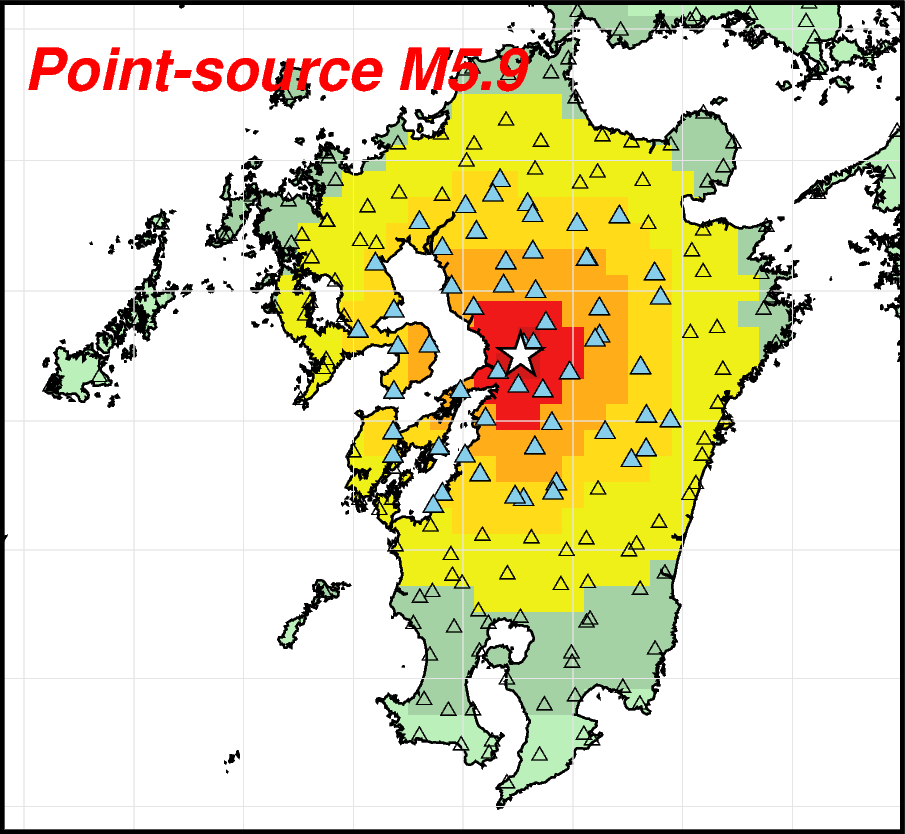

In [9]:
def predict_gmpe(magnitude):
    distance = stations["SRhypo"].to_numpy()
    vs30 = stations["Vs30"].to_numpy()
    if settings["gmpe"] == "Chao":
        pga_g, *_ = Chao19H(
            0, magnitude, distance, depth, vs30, -999,
            0, 1, 0, 0, 0, 0, 0, 0,  # strike-slip crustal flags, measured Vs30
        )
        return pga_g.flatten() * 980 * 1.22
    from GMPE_Zhao06 import Zhao06
    pga_gal, _ = Zhao06(magnitude, distance, depth, vs30, rake=0.0)
    return pga_gal * 1.2


def plot_pga_map(pga, observed=False):
    """Original PyGMT surface map: PGA colors, coast, stations and epicenter."""
    taiwan = settings["gmpe"] == "Chao"
    region = [119.4, 122.3, 21.7, 25.35] if taiwan else [128.4, 132.5, 30.9, 34.1]
    x = stations["Longitude"].to_numpy()
    y = stations["Latitude"].to_numpy()
    fig = pygmt.Figure()
    with pygmt.config(
        FONT_ANNOT_PRIMARY="10p,Helvetica,black", MAP_FRAME_TYPE="plain",
        MAP_FRAME_PEN="1p,black", MAP_GRID_PEN_PRIMARY="0.2p,gray90",
        MAP_TICK_LENGTH_PRIMARY="0.1c", FORMAT_GEO_MAP="ddd",
    ):
        pygmt.makecpt(cmap=str(ROOT / "PGA_colorbar.cpt"))
        fig.basemap(region=region, projection="M3i", frame=["lbrt", "x1f0.5g1", "y1f0.5g1"])
        grid = pygmt.surface(
            x=x, y=y, z=pga, region=region, spacing=0.05 if taiwan else 0.1,
            tension=0.15, registration="gridline",
        )
        fig.grdimage(grid=grid, cmap=True, transparency=10)
        if taiwan:
            fig.plot(data=str(ROOT / "TW_city_boundary.txt"), pen="0.3p,white" if observed else "0.3p,darkgray")
        fig.coast(water="white", shorelines="0.5p,black", frame=["lbrt", "x1f0.5g0.5", "y1f0.5g0.5"])
        fig.plot(x=x, y=y, style="t0.2c" if taiwan else "t0.15c", pen="0.2p,black")
        above_threshold = pga >= 25
        if above_threshold.any():
            fig.plot(x=x[above_threshold], y=y[above_threshold], style="t0.2c", fill="skyblue", pen="0.2p,black")
        if observed and taiwan:
            mechanisms = {
                1: (212.86, 40.33, 103.11, 121.85, 23.65),
                3: (269.71, 33.86, 14.97, 120.0, 22.5),
                4: (210.48, 56.31, 40.38, 121.82, 23.2),
            }
            strike, dip, rake, lon, lat = mechanisms[EVENT_ID]
            fig.plot(x=[lon, float(event["hypolon"])], y=[lat, float(event["hypolat"])], pen="0.3p,black")
            fig.meca(spec=dict(strike=strike, dip=dip, rake=rake, magnitude=7),
                     scale="0.6c", longitude=lon, latitude=lat, depth=16.7,
                     compressionfill="darkgray", extensionfill="cornsilk", pen="0.5p,black")
            fig.basemap(map_scale="jBL+w50k+o0.9c/1.0c")
        fig.plot(x=float(event["hypolon"]), y=float(event["hypolat"]),
                 style="a0.4c", fill="gold" if observed else "white", pen="0.5p,black")
        label = "Final PGA" if observed else f"Point-source M{settings['magnitude']}"
        fig.text(x=region[0] + 0.1, y=region[3] - 0.25, text=label,
                 justify="ML", font="14p,Helvetica-BoldOblique,red")
        if observed:
            pygmt.makecpt(cmap=str(ROOT / "intensity_colorbar.cpt"), series=[0, 10],
                          color_model="+c0,2.5,8.0,15.0,25.0,40.0,80.0,150.0,250.0,400.0")
            if taiwan:
                fig.colorbar(position="jBR+o1c/0.2c+v+w3c/0.3c")
                fig.text(x=region[1] - 0.15, y=region[2] + 1.2, text="PGA (gal)", justify="TR", font="8p,Helvetica")
            else:
                with pygmt.config(FONT_ANNOT_PRIMARY="10p,Helvetica", FONT_LABEL="11p,Helvetica",
                                  MAP_ANNOT_OFFSET_PRIMARY="0.12c", MAP_LABEL_OFFSET="0.15c"):
                    fig.colorbar(position="JMR+o0.5c/0c+v+w5c/0.35c",
                                 frame=["x", "y+lPGA (gal)"])
            if not taiwan:
                with fig.inset(region=[127, 146, 30, 46], projection="M2c",
                               position="jBL+o0.14c", box="+p0.5p,black+gwhite"):
                    fig.coast(dcw="JP+glightgray+p0.1p", area_thresh=10000)
                    fig.plot(data=[[region[0], region[2], region[1], region[3]]], style="r+s", pen="0.7p,blue")
    return fig

gmpe_initial = predict_gmpe(settings["magnitude"])
gmpe_map = plot_pga_map(gmpe_initial)
gmpe_map.show()


## 2. Final PGA distribution

`EndRealPGA` is the final observed PGA at each station. Use the original
PyGMT surface interpolation, PGA palette, station markers and epicenter.
Taiwan retains its city boundaries and focal mechanism; Japan retains its inset.
The deleted Japan administrative boundaries and aftershock catalog are not used.

surface [WARNING]: 22 unusable points were supplied; these will be ignored.
surface [WARNING]: You should have pre-processed the data with block-mean, -median, or -mode.
surface [WARNING]: Check that previous processing steps write results with enough decimals.
surface [WARNING]: Possibly some data were half-way between nodes and subject to IEEE 754 rounding.


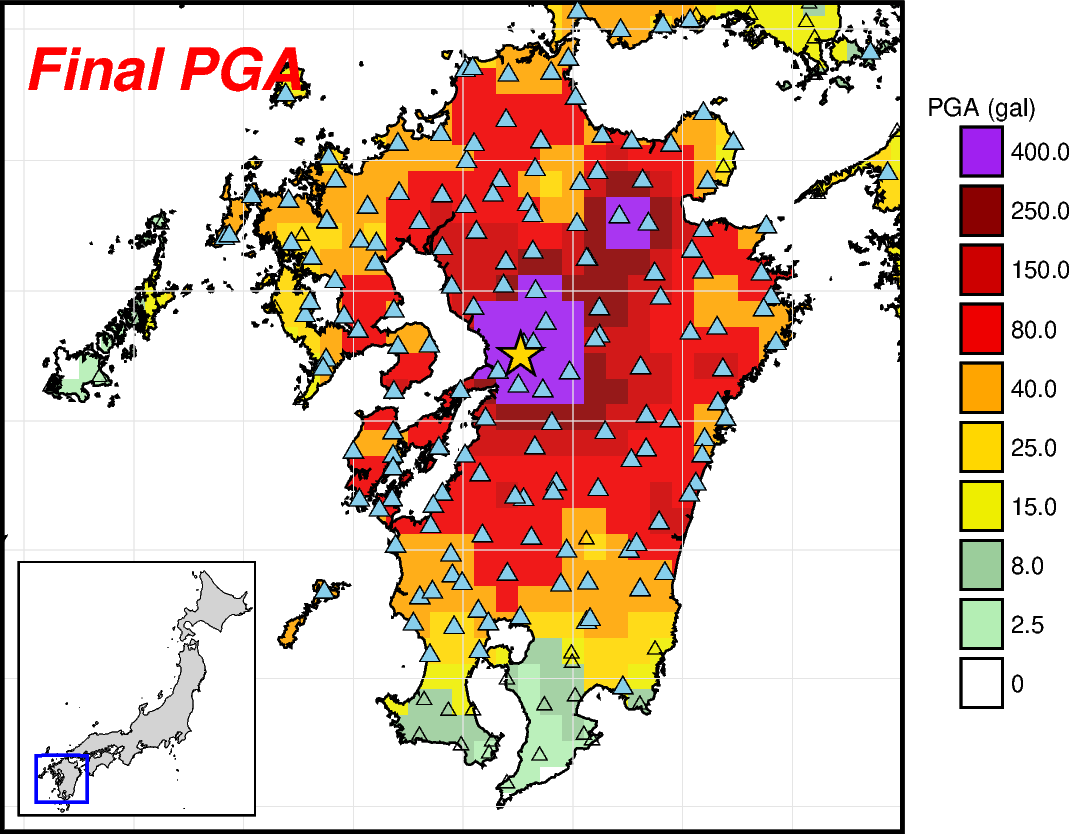

In [10]:
final_pga = stations["EndRealPGA"].to_numpy()
positive = final_pga > 0
final_pga_map = plot_pga_map(final_pga, observed=True)
final_pga_map.show()


## 3. Least-square fitting

Fit the GMPE prediction, **not the observed final PGA**, to initialize the filter:

\[
\ln(PGA) = c_2(\ln R)^2 + c_1\ln R + c_{Vs30}\ln(Vs30/760) + c_0.
\]

The two directional coefficients start at zero and are learned during KF updates.

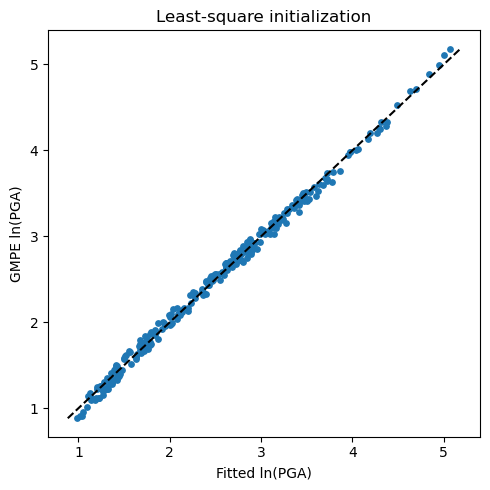

Initial [c2, c1, c_vs30, c0, c_cos, c_sin]: [-0.25451725  0.73566657 -0.18342252  4.65495341  0.          0.        ]


In [11]:
G_fit = design_matrix(stations, directional=False)
ln_gmpe_initial = np.log(gmpe_initial)
fit_coefficients = np.linalg.lstsq(G_fit, ln_gmpe_initial, rcond=None)[0]
ln_fitted = G_fit @ fit_coefficients
initial_state = np.r_[fit_coefficients, 0.0, 0.0]

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(ln_fitted, ln_gmpe_initial, s=15)
limits = [min(ln_fitted.min(), ln_gmpe_initial.min()), max(ln_fitted.max(), ln_gmpe_initial.max())]
ax.plot(limits, limits, "k--")
ax.set(xlabel="Fitted ln(PGA)", ylabel="GMPE ln(PGA)", title="Least-square initialization")
fig.tight_layout()
plt.show()
print("Initial [c2, c1, c_vs30, c0, c_cos, c_sin]:", initial_state)


## 4. KF update

At each second, use stations inside `V_APP × (t − depth / VS_TRUE)` and update
the six coefficients using the current `RealPGA`, then predict PGA at all stations:

\[
\ln(PGA) = c_2(\ln R)^2+c_1\ln R+c_{Vs30}\ln(Vs30/760)+c_0
            +c_{cos}\cos\theta+c_{sin}\sin\theta.
\]

To retain the source calculation, Taiwan replaces zero PGA by `1e-10` and uses
the simple covariance update; Japan excludes zero PGA and uses the Joseph update.
`coefficient_history` and `pga_history` hold the per-update results in memory.

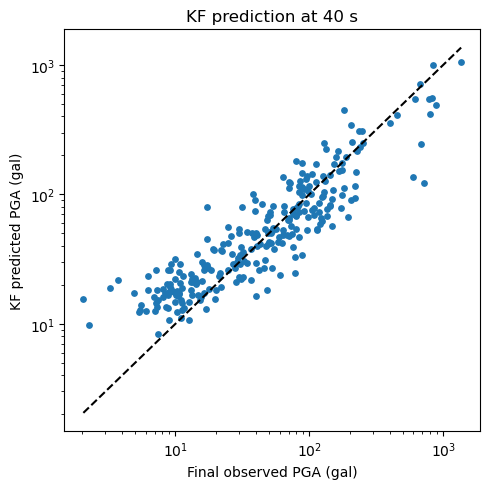

30 updates; final coefficients: [-0.27039134  0.68427768 -0.14582773  6.56930311  0.11543234  0.33344091]


In [12]:
state = initial_state.copy()
covariance = np.zeros((6, 6))
G_all = design_matrix(stations)
coefficient_rows, prediction_rows, update_times = [], [], []

for second in range(settings["start"], END_SECOND + 1):
    if second not in data.index:
        continue
    current = data.loc[[second]]
    wave_front = V_APP * (second - depth / VS_TRUE)
    arrived = current[current["SRepi"] <= wave_front]
    if settings["gmpe"] == "Zhao06":
        arrived = arrived[arrived["RealPGA"] > 0]
    if len(arrived) < MIN_STATIONS:
        continue
    arrived = arrived.sort_values("SRhypo")
    observed = arrived["RealPGA"].to_numpy()
    ln_observed = np.log(np.where(observed == 0, 1e-10, observed))
    H = design_matrix(arrived)
    R_obs = np.eye(len(arrived)) * OBS_VARIANCE

    covariance = covariance + Q
    PHt = covariance @ H.T
    innovation_covariance = H @ covariance @ H.T + R_obs
    gain = np.linalg.solve(innovation_covariance.T, PHt.T).T
    state = state + gain @ (ln_observed - H @ state)
    IKH = np.eye(6) - gain @ H
    if settings["gmpe"] == "Zhao06":
        covariance = IKH @ covariance @ IKH.T + gain @ R_obs @ gain.T
    else:
        covariance = IKH @ covariance

    update_times.append(second)
    coefficient_rows.append(state.copy())
    prediction_rows.append(np.exp(G_all @ state))

if not update_times:
    raise ValueError("No KF update: check the time interval and station selection.")
coefficient_history = pd.DataFrame(
    coefficient_rows, index=pd.Index(update_times, name="second"),
    columns=["c2", "c1", "c_vs30", "c0", "c_cos", "c_sin"],
)
pga_history = pd.DataFrame(
    prediction_rows, index=pd.Index(update_times, name="second"),
    columns=pd.MultiIndex.from_frame(stations[["Station", "Longitude", "Latitude"]]),
)
kf_pga = pga_history.iloc[-1].to_numpy()
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(final_pga[positive], kf_pga[positive], s=15)
limits = [min(final_pga[positive].min(), kf_pga[positive].min()), max(final_pga[positive].max(), kf_pga[positive].max())]
ax.plot(limits, limits, "k--")
ax.set(xscale="log", yscale="log", xlabel="Final observed PGA (gal)", ylabel="KF predicted PGA (gal)", title=f"KF prediction at {update_times[-1]} s")
fig.tight_layout()
plt.show()
print(f"{len(update_times)} updates; final coefficients:", state)
